# Financial risk: VaR and Expected Shortfall

Filtered historical simulation: select converged volatility model by training AIC, estimate standardized residual tail quantiles on training only, scale by one-step forecast volatility. Loss is negative percent log return. Kupiec and exact binomial coverage tests assess exceedance frequency, not independence or ES calibration.

All returns are calculated from supplied adjusted close values; official exchange calendar and corporate actions are unverified. Observation steps may span missing trading dates.

In [1]:
from pathlib import Path
import sys
root=Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
sys.path.insert(0,str(root/"scripts"))
from remaining_models import risk
result=risk()
display(result)

,Company,Model,Confidence,N,Breaches,Expected,Mean_VaR,Mean_ES,Kupiec_p,Exact_binomial_p
0,JKH,GJR-GARCH,0.95,594,32,29.70,1.962099,3.042478,0.668745,0.637563
1,JKH,GJR-GARCH,0.99,594,6,5.94,3.268152,5.305929,0.980293,0.837239
2,HAYL,EGARCH,0.95,545,19,27.25,2.601567,3.947677,0.087087,0.115202
3,HAYL,EGARCH,0.99,545,3,5.45,4.579560,6.388355,0.248967,0.389438
4,VONE,GJR-GARCH,0.95,582,19,29.10,2.793212,3.923280,0.040807,0.056522
5,VONE,GJR-GARCH,0.99,582,5,5.82,4.481952,5.723211,0.726293,1.000000


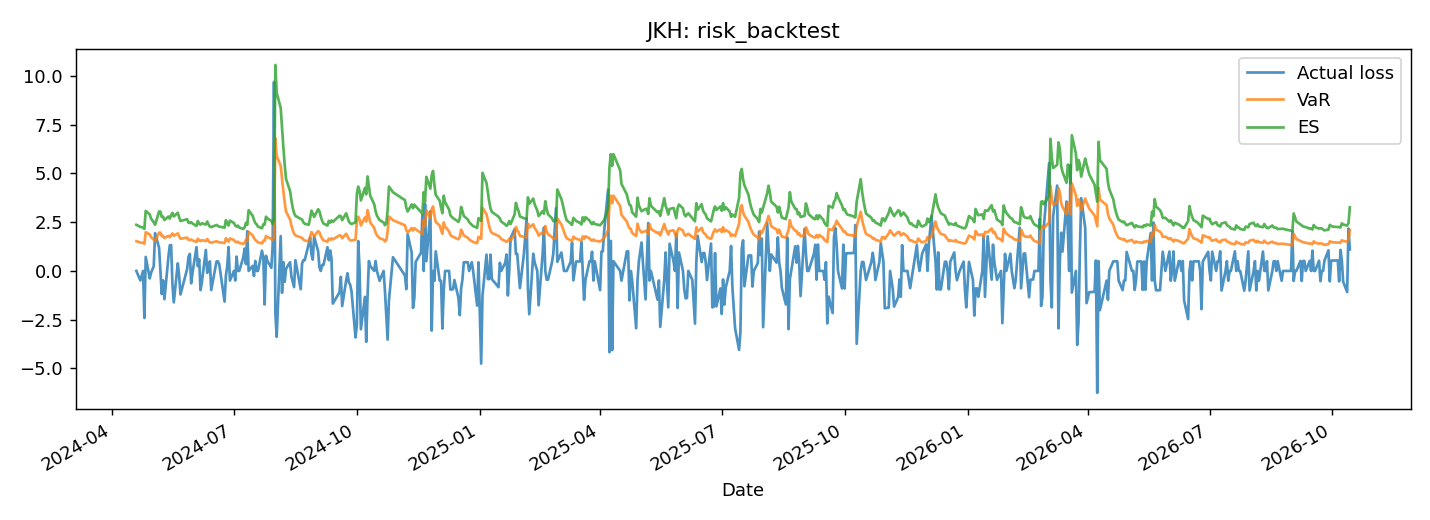

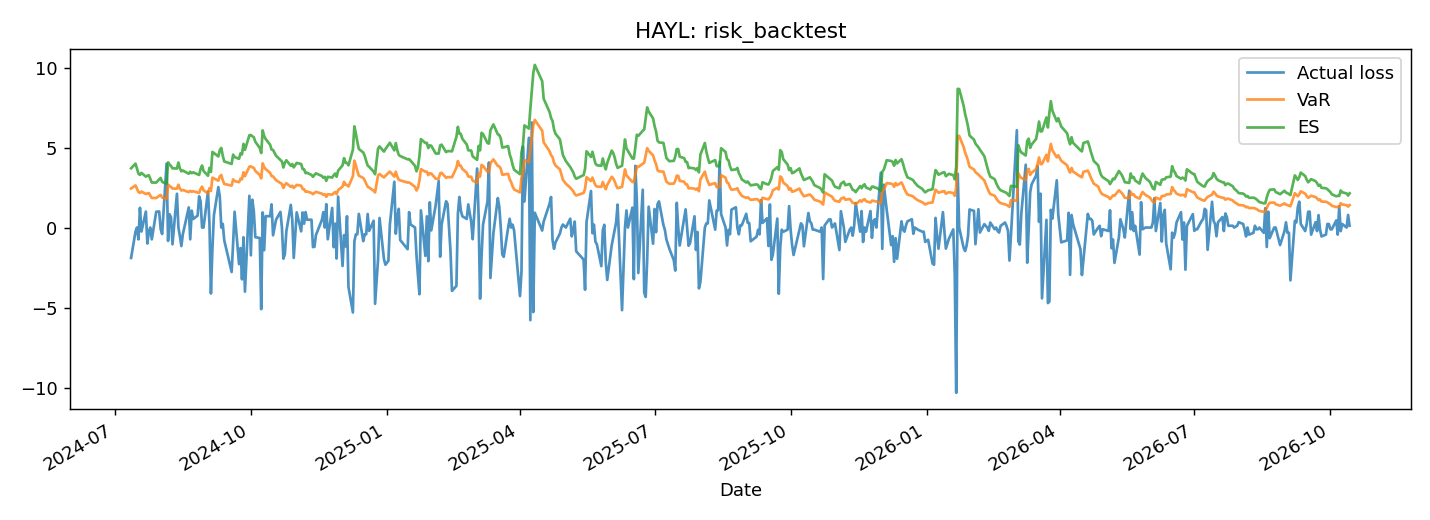

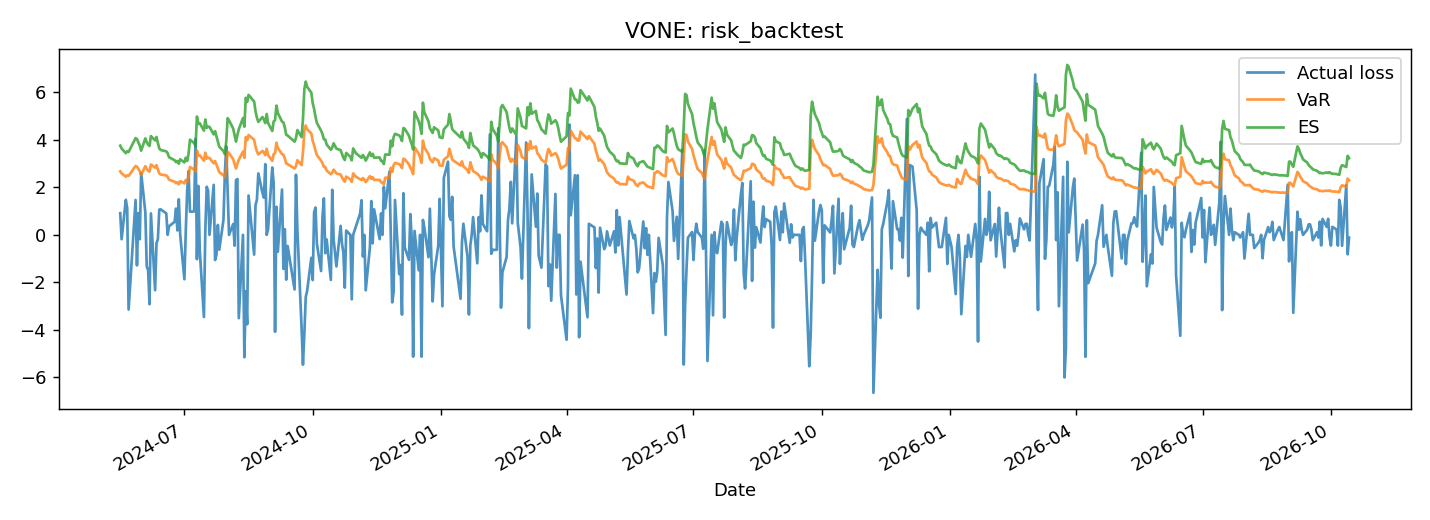

In [2]:
import pandas as pd
from IPython.display import display, Image
for asset in ["JKH","HAYL","VONE"]:
    display(Image(filename=str(root/"outputs/figures/risk_backtest"/(asset+".png"))))

## Interpretation and limitations
The VONE 95% Kupiec test rejects nominal coverage at 5% in the supplied run; the exact binomial test does not. Do not claim universal risk calibration.